In [1]:
#Import required libraries

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
#Prepare the dataset
# Remove missing values
df = df.dropna(
    subset=['Complaint_Description', 'Department']
).copy()

# Convert values into strings
df['Complaint_Description'] = (
    df['Complaint_Description'].astype(str)
)

df['Department'] = df['Department'].astype(str)

# Remove empty complaint descriptions
df = df[
    df['Complaint_Description'].str.strip() != ''
]

# Display dataset
print(df[['Complaint_Description', 'Department']].head())

print("Total training records:", len(df))
print("Total Departments:", df['Department'].nunique())

                               Complaint_Description              Department
0  Eve teasing Adhartal area mein badh gayi hai, ...  Police & Law and Order
1  à¤¶à¥à¤°à¤®à¤¿à¤• à¤•à¤¾à¤°à¥à¤¡ Ranchi à¤®à...     Employment & Labour
2  Dear officer, à¤¸à¤¡à¤¼à¤• à¤ªà¤° à¤¬à¤¿à¤¨à¤¾...  Roads & Infrastructure
3  à¤ªà¤¿à¤›à¤²à¥‡ a month à¤¸à¥‡ à¤¹à¤®à¤¾à¤°à¥‡...            Water Supply
4  Namaste sir, à¤¸à¤°à¤•à¤¾à¤°à¥€ à¤¸à¥à¤•à¥‚à¤...     Education & Schools
Total training records: 1571
Total Departments: 14


In [4]:
import pandas as pd

# Load dataset
df = pd.read_excel("CitizenGrievance.xlsx")

# Display first five records
print("First five records:")
print(df.head())

# Display dataset information
print("\nDataset Information:")
print(df.info())

# Identify structured and unstructured columns
structured_columns = ['Complaint_id', 'State', 'Date']
unstructured_columns = ['Complaint_Description']

print("\nStructured Data:")
print(df[structured_columns].head())

print("\nUnstructured Data:")
print(df[unstructured_columns].head())

First five records:
  Complaint_id                              Complaint_Description  \
0    GRV101340  Eve teasing Adhartal area mein badh gayi hai, ...   
1    GRV102878  à¤¶à¥à¤°à¤®à¤¿à¤• à¤•à¤¾à¤°à¥à¤¡ Ranchi à¤®à...   
2    GRV100497  Dear officer, à¤¸à¤¡à¤¼à¤• à¤ªà¤° à¤¬à¤¿à¤¨à¤¾...   
3    GRV100019  à¤ªà¤¿à¤›à¤²à¥‡ a month à¤¸à¥‡ à¤¹à¤®à¤¾à¤°à¥‡...   
4    GRV101868  Namaste sir, à¤¸à¤°à¤•à¤¾à¤°à¥€ à¤¸à¥à¤•à¥‚à¤...   

               Department       Date        State ResolutionDate  
0  Police & Law and Order 2025-02-17  Maharashtra     2025-02-28  
1     Employment & Labour 2025-07-02      Manipur     2025-07-31  
2  Roads & Infrastructure 2025-08-30        Bihar     2025-09-26  
3            Water Supply 2025-09-22    Rajasthan     2025-10-06  
4     Education & Schools 2025-04-05       Punjab     2025-04-17  

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1571 entries, 0 to 1570
Data columns (total 6 columns):
 #   Column                 Non-Null Count  Dt

In [6]:
#Prepare the dataset
# Remove missing values
df = df.dropna(
    subset=['Complaint_Description', 'Department']
).copy()

# Convert values into strings
df['Complaint_Description'] = (
    df['Complaint_Description'].astype(str)
)

df['Department'] = df['Department'].astype(str)

# Remove empty complaint descriptions
df = df[
    df['Complaint_Description'].str.strip() != ''
]

# Display dataset
print(df[['Complaint_Description', 'Department']].head())

print("Total training records:", len(df))
print("Total Departments:", df['Department'].nunique())


                               Complaint_Description              Department
0  Eve teasing Adhartal area mein badh gayi hai, ...  Police & Law and Order
1  à¤¶à¥à¤°à¤®à¤¿à¤• à¤•à¤¾à¤°à¥à¤¡ Ranchi à¤®à...     Employment & Labour
2  Dear officer, à¤¸à¤¡à¤¼à¤• à¤ªà¤° à¤¬à¤¿à¤¨à¤¾...  Roads & Infrastructure
3  à¤ªà¤¿à¤›à¤²à¥‡ a month à¤¸à¥‡ à¤¹à¤®à¤¾à¤°à¥‡...            Water Supply
4  Namaste sir, à¤¸à¤°à¤•à¤¾à¤°à¥€ à¤¸à¥à¤•à¥‚à¤...     Education & Schools
Total training records: 1571
Total Departments: 14


In [7]:
#Split the dataset into training and testing data
X = df['Complaint_Description']
y = df['Department']

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))



Training Records: 1256
Testing Records: 315


In [8]:

#Build the supervised classification model
# Create machine learning pipeline
model = Pipeline([
    ('tfidf', TfidfVectorizer(
        stop_words='english',
        max_features=5000,
        ngram_range=(1, 2)
    )),

    ('classifier', LogisticRegression(
        max_iter=1000,
        class_weight='balanced'
    ))
])

# Train the model
model.fit(X_train, y_train)

print("Complaint Classification Model Trained Successfully!")

Complaint Classification Model Trained Successfully!


In [9]:
#6. Evaluate model performance

# Predict departments for test data
y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))



Model Accuracy: 96.51 %

Classification Report:
                                     precision    recall  f1-score   support

       Banking & Financial Services       0.96      1.00      0.98        24
               Corruption & Bribery       1.00      1.00      1.00        25
                Education & Schools       0.85      0.92      0.88        25
                        Electricity       1.00      1.00      1.00        18
                Employment & Labour       1.00      0.85      0.92        27
             Healthcare & Hospitals       0.96      0.96      0.96        23
             Land Records & Revenue       1.00      1.00      1.00        25
             Municipal Certificates       1.00      1.00      1.00        20
           Pension & Provident Fund       0.92      1.00      0.96        23
             Police & Law and Order       1.00      1.00      1.00        23
Ration & Public Distribution System       0.92      1.00      0.96        23
             Roads & Infras

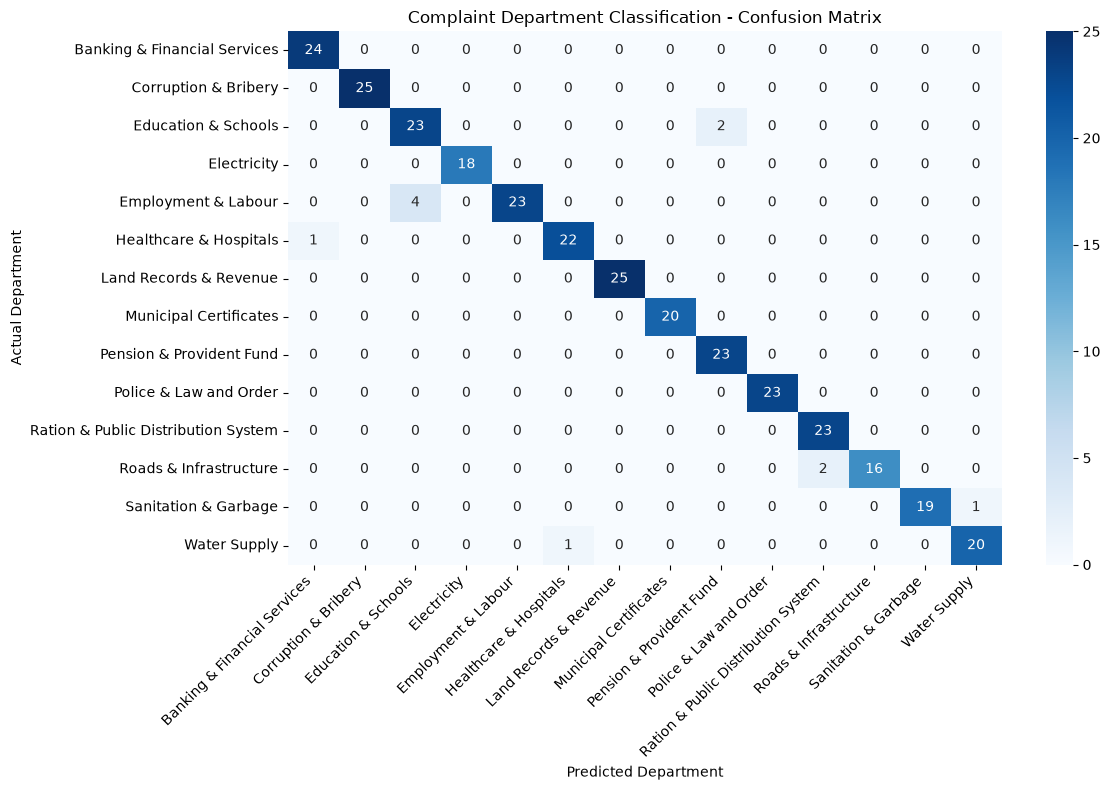

In [10]:
# Visualize the classification results

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(12, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.title('Complaint Department Classification - Confusion Matrix')
plt.xlabel('Predicted Department')
plt.ylabel('Actual Department')

plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [11]:

#Automatically route a new complaint
# New complaint
new_complaint = [
    "There is no proper drinking water supply "
    "in our village for the last five days."
]

# Predict department
predicted_department = model.predict(new_complaint)

print("New Complaint:", new_complaint[0])

print("Automatically Assigned Department:",
      predicted_department[0])

# Display prediction confidence
probabilities = model.predict_proba(new_complaint)[0]

confidence = max(probabilities) * 100

print("Prediction Confidence:",
      round(confidence, 2), "%")

New Complaint: There is no proper drinking water supply in our village for the last five days.
Automatically Assigned Department: Water Supply
Prediction Confidence: 43.96 %


In [12]:
message = """
A lightweight conventional ML model like Logistic Regression was chosen
because it requires less computational power, memory, and training time
compared to Deep Neural Networks or BERT.

It performs effectively on text-classification tasks, especially when
using TF-IDF features and a reasonably labelled dataset.

Training a DNN or BERT from scratch requires large datasets, powerful
hardware, and significantly more resources.

Therefore, Logistic Regression provides a cost-effective, faster,
and easier-to-implement solution for this complaint-routing prototype.
"""

print(message)




A lightweight conventional ML model like Logistic Regression was chosen
because it requires less computational power, memory, and training time
compared to Deep Neural Networks or BERT.

It performs effectively on text-classification tasks, especially when
using TF-IDF features and a reasonably labelled dataset.

Training a DNN or BERT from scratch requires large datasets, powerful
hardware, and significantly more resources.

Therefore, Logistic Regression provides a cost-effective, faster,
and easier-to-implement solution for this complaint-routing prototype.

